# Problem Background: The Great Migration

**Year: 3050**

The world as we knew it has changed drastically. After decades of conflict, disease, and a relentless zombie apocalypse, the human race faces extinction. The relentless hordes of the undead have ravaged cities, reduced populations, and devastated the planet's ecosystems.

In a desperate bid for survival, the remaining factions of humanity have united to embark on a monumental journey to a new home: **Earth Junior**, a distant planet believed to be free from the scourge of the undead.

As they prepare for this monumental journey, the survival of the human race hinges on their ability to screen potential passengers at the spaceship station. It is crucial that no zombies are allowed to enter the spacecraft, as even a single infected individual could jeopardize the entire mission and the future of humanity.

In this dire situation, you find yourself as the last surviving machine learning engineer, tasked with developing a screening model to predict the zombie-ness of a person. A high human-zombie score would mean the person is likely to be a zombie. The fate of the human race depends on your expertise in machine learning, and you must create a reliable system to ensure the success of this migration to 'Earth Junior'.


# Task 1 -- Linear Regression  

### Introduction

In this assignment, you will be implementing Linear Regression and Logistic Regression models for the provided dataset from scratch, and will be familiarizing yourself with the corresponding scikit-learn APIs. A description of the problem statement is given at the start of each part.

After this notebook you should be able to:

- Set up simple regression tasks.

- Understand the working of Linear Regression models and simple data preprocessing.

- Implement Linear Regression models using simple `numpy`.

Have fun!



# Human-Zombie Dataset

This dataset simulates human and zombie characteristics based on various lifestyle and physical traits. The dataset contains 1,000 entries, each with features that correlate with a continuous "Human-Zombie Score" ranging from 0 (complete human) to 100 (complete zombie).

This generation of human race has smart-chips embedded in their bloodstream that can keep track of and record all these features.

## Features

- **Height (cm):** The height of the individual measured in centimeters, it decreases with zombie score because zombies are known to shrink in height.

- **Weight (kg):** The weight of the individual measured in kilograms. Zombies tend to have a lower weight because of loss of muscle mass, tissue, organs (and soul??).

- **Screen Time (hrs):** The average number of hours spent in front of screens daily. This feature increases with the human-zombie score, reflecting a more sedentary lifestyle.

- **Junk Food (days/week):** The average number of days per week the individual consumes junk food. This feature also increases with the human-zombie score, indicating poorer dietary habits.

- **Physical Activity (hrs/week):** The total hours spent on physical activities per week. This feature decreases as the human-zombie score increases, suggesting a decline in physical activity.

- **Task Completion (scale):** Scale from 0 to 10 representing how often tasks are completed on time (0 = always on time, 10 = never on time). This score decreases with a higher human-zombie score, indicating declining productivity.

- **Human-Zombie Score:** A continuous score from 0 to 100 representing the degree of "zombie-ness" of the individual, where 0 is fully human and 100 is completely zombie-like.

## Usage

This dataset can be used for various analyses, including regression modeling to predict the human-zombie score based on lifestyle and physical traits.


## Multivariate Linear Regression

In this part, you will implement multivariate linear regression (from scratch) to predict the the human-zombie score during screening before the person can be allowed to enter the spaceship.

To do this, you have the human-zombie-datset.csv containing 1000 examples of the features described above and their scores.

Each one of these input features is stored using a different scale. The features include ranges 0-10, 17-100 and some between 130-200.  This is often the case with real-world data, and understanding how to explore and clean such data is an important skill to develop.

A common way to normalize features that use different scales and ranges is:

- Subtract the mean value of each feature from the dataset.

- After subtracting the mean, additionally scale (divide) the feature values by their respective standard deviations.

Note: We only use examples of the train set to estimate the mean and standard deviation.

You have to follow exactly the same steps as above i.e. implement hypothesis, cost function and gradient descent for multivariate linear regression to learn parameters $\theta$ using train set. Finally, report the cost (error) using your learned parameters $\theta$ on test set.








### What is Linear Regression?

Linear regression is a fundamental machine learning algorithm that models the relationship between a dependent variable (target) and one or more independent variables (features) using a linear equation.

**The Linear Regression Equation:**

For multivariate linear regression (multiple features), the hypothesis function is:

$$h_\theta(x) = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + ... + \theta_n x_n$$

Or in matrix form:
$$h_\theta(x) = \theta^T x$$

Where:
- $h_\theta(x)$ = predicted value (Human-Zombie Score in our case)
- $\theta_0$ = bias term (intercept)
- $\theta_1, \theta_2, ..., \theta_n$ = weights/parameters for each feature
- $x_1, x_2, ..., x_n$ = input features (Height, Weight, Screen Time, etc.)

### What Do We Actually Find in Linear Regression?

Linear regression aims to find the **optimal parameters** $\theta$ that best fit our data. These parameters represent:

1. **$\theta_0$ (Bias)**: The baseline Human-Zombie Score when all features are zero
2. **$\theta_1$ (Height coefficient)**: How much the score changes per cm of height
3. **$\theta_2$ (Weight coefficient)**: How much the score changes per kg of weight
4. **And so on for each feature...**

The goal is to find the $\theta$ values that minimize the difference between our predictions and actual Human-Zombie Scores!

---

## Cost Functions: Measuring Our Mistakes

A cost function measures how wrong our predictions are. Different cost functions have different properties and use cases.

### 1. Mean Squared Error (MSE) - Most Common
$$J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)})^2$$

**Properties:**
- Penalizes large errors heavily (squared term)
- Differentiable everywhere (good for gradient descent)
- Sensitive to outliers

### 2. Mean Absolute Error (MAE) - Robust to Outliers
$$J(\theta) = \frac{1}{m} \sum_{i=1}^{m} |h_\theta(x^{(i)}) - y^{(i)}|$$

**Properties:**
- Linear penalty for errors
- More robust to outliers than MSE
- Not differentiable at zero (can cause issues in optimization)

### 3. Root Mean Squared Error (RMSE) - Interpretable Scale
$$J(\theta) = \sqrt{\frac{1}{m} \sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)})^2}$$

**Properties:**
- Same scale as the target variable
- Easy to interpret (error in same units as Human-Zombie Score)
- Still sensitive to outliers like MSE

### When to Use Which Cost Function?

- **MSE**: Default choice, works well when you want to penalize large errors
- **MAE**: When your data has outliers or you want equal penalty for all errors
- **RMSE**: When you want interpretable error metrics in the same scale as your target

---

### Part A: Implementation from Scratch

#### Imports

Start off with importing in the required libraries. Note that you are **only** allowed to use `sklearn`'s train_test_split in this part and no other function from `sklearn`.

In [ ]:
import numpy as np
import pandas as pd

#### Preparing Data

Load in your dataset and perform train-test split. Apply preprocessing steps to cater to missing values, categorical variables etc. if necessary.

In [ ]:
# Load the Human-Zombie dataset
# The target column is "Human-Zombie Score"; all other columns are input features.

df = pd.read_csv("/content/human_zombie_dataset_v5.csv")


# Display basic information so we can verify the data before modeling.
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)


Dataset shape: (1000, 7)

First 5 rows:


,Height (cm),Weight (kg),Screen Time (hrs),Junk Food (days/week),Physical Activity (hrs/week),Task Completion (scale),Human-Zombie Score
0,157,41,8.455099,5.622736,4.474819,6.166119,54.881350
1,151,40,8.581430,5.922744,3.749707,1.084877,71.518937
2,166,45,5.018847,5.746557,4.596662,2.030814,60.276338
3,160,75,6.417010,4.634547,4.546153,3.360430,54.488318
4,153,74,4.417465,4.740153,6.601801,5.758603,42.365480



Missing values:
Height (cm)                     0
Weight (kg)                     0
Screen Time (hrs)               0
Junk Food (days/week)           0
Physical Activity (hrs/week)    0
Task Completion (scale)         0
Human-Zombie Score              0
dtype: int64

Data types:
Height (cm)                       int64
Weight (kg)                       int64
Screen Time (hrs)               float64
Junk Food (days/week)           float64
Physical Activity (hrs/week)    float64
Task Completion (scale)         float64
Human-Zombie Score              float64
dtype: object


In [ ]:
from sklearn.model_selection import train_test_split

# Separate input features (X) from the target (y).
target_column = "Human-Zombie Score"

X = df.drop(columns=[target_column])
y = df[target_column].to_numpy()

# Split the data BEFORE fitting any preprocessing parameters.
# random_state makes the split reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)


X_train shape: (800, 6)
X_test shape : (200, 6)
y_train shape: (800,)
y_test shape : (200,)


#### Normalizing Data  

For models like Linear/Logistic Regression, and even for Neural Networks, Standardization/Normalization is a non-negotiable step in the preprocessing stage. You would find your model **broken** if you do not normalize your data.

One nice way to implement this is to create a class, `StandardScaler` that can be used to store the mean and standard deviation of each feature of the training set. The `StandardScaler` class also has two functions, `fit` and `transform`.

- The `fit` function is used to calculate the mean and standard deviation of each feature of the training set.

- The `transform` function is used to transform all the features using the corresponding mean and standard deviation, i.e. subtracting the mean and dividing by the standard deviation.

A very subtle and important point to note here is that the mean and standard deviation should be calculated only on the training set, and then applied to the test set. This is because in real-world scenarios, we do not have access to the test set, and hence we cannot calculate the mean and standard deviation of the test set.

In [ ]:
# IMPORTANT:
# Part A says that sklearn should only be used for train_test_split.
# Therefore, we implement standardization ourselves instead of using sklearn's StandardScaler.

class StandardScalerScratch:
    """Simple StandardScaler implemented from scratch."""

    def fit(self, X):
        # Convert DataFrame to NumPy so the mathematical operations are consistent.
        X = np.asarray(X, dtype=float)

        # Calculate statistics ONLY from the training data.
        self.mean_ = np.mean(X, axis=0)
        self.scale_ = np.std(X, axis=0)

        # Avoid division by zero if a feature has zero variance.
        self.scale_[self.scale_ == 0] = 1.0

        return self

    def transform(self, X):
        # Apply the SAME training mean/std to any dataset.
        X = np.asarray(X, dtype=float)
        return (X - self.mean_) / self.scale_

    def fit_transform(self, X):
        # Fit first, then transform the same training data.
        return self.fit(X).transform(X)

    def inverse_transform(self, Z):
        # Convert standardized values back to the original scale.
        Z = np.asarray(Z, dtype=float)
        return Z * self.scale_ + self.mean_


# Fit only on X_train.
scaler = StandardScalerScratch()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training means:", scaler.mean_)
print("Training standard deviations:", scaler.scale_)

# Check that the training features are approximately mean=0 and std=1.
print("\nScaled training means:", np.mean(X_train_scaled, axis=0))
print("Scaled training stds :", np.std(X_train_scaled, axis=0))


Training means: [155.6575      58.10875      6.49052518   4.44925149   5.05423437
   4.99272468]
Training standard deviations: [12.58452199 15.04275319  2.49661353  1.52081147  2.96409383  2.9776557 ]

Scaled training means: [ 1.11022302e-16 -3.99680289e-17 -3.99680289e-17 -3.24185123e-16
  6.21724894e-17 -1.68753900e-16]
Scaled training stds : [1. 1. 1. 1. 1. 1.]


## Gradient Descent: The Mathematical Journey to Minimum

### What is Gradient Descent?

Imagine you're a zombie trying to find the lowest point in a valley (minimum cost) while blindfolded. Gradient descent is like feeling the slope of the ground and taking steps in the steepest downhill direction!

### The Mathematics Behind Gradient Descent

**The Gradient**: The gradient $\nabla J(\theta)$ tells us the direction of steepest increase in our cost function.

For MSE cost function, the gradient with respect to each parameter is:

$$\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} \sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)}) x_j^{(i)}$$

**The Update Rule**: We move in the opposite direction of the gradient:

$$\theta_j := \theta_j - \alpha \frac{\partial J(\theta)}{\partial \theta_j}$$

Where:
- $\alpha$ = learning rate (how big steps we take)
- $\frac{\partial J(\theta)}{\partial \theta_j}$ = partial derivative (slope) of cost function

### How We Calculate Gradients Step by Step:

1. **Forward Pass**: Calculate predictions using current $\theta$
2. **Calculate Error**: Find difference between predictions and actual values
3. **Calculate Gradients**: Use the error to compute how much to change each $\theta$
4. **Update Parameters**: Move $\theta$ in the direction that reduces cost
5. **Repeat**: Until convergence or maximum iterations


#### Gradient Descent Implementation




Now that your data is ready, you can start implementing the gradient descent algorithm.

You should be creating a class `LinearRegression`. This means implementing the following methods:

- `__init__`: The constructor of the class. You can initialize any variables, like the learning rate and the number of iterations, here.

- `fit`: This method will be used to train your model. It should take in the training data and labels as parameters, and learn the parameters using gradient descent. Save the loss values after every iteration in a list, and return it (for plotting later).

- `predict`: This method will be used to predict the labels for a given set of test data. It should take in the test data as a parameter, and return the predicted labels.

- `score`: This method will be used to calculate the mean square error for the test data. It should take in the test data and labels as parameters, and return the mean square error. Note that this is a unique case where the loss function and the final reported metric are the same.




1. Implement the `LinearRegression` class with support for different cost functions
2. Add methods for MSE, MAE, and RMSE
3. Compare how different cost functions affect the learning process
4. Visualize the gradient descent path

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


class LinearRegression:
    """Multivariate Linear Regression trained with gradient descent.

    Supported cost functions:
    - mse  : Mean Squared Error (with 1/(2m) convention)
    - mae  : Mean Absolute Error
    - rmse : Root Mean Squared Error
    """

    def __init__(self, learning_rate=0.01, num_iterations=1000,
                 cost_function='mse'):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.cost_function = cost_function.lower()

        # These will be populated during training.
        self.cost_history = []
        self.theta_history = []
        self.theta = None
        self.X_mean = None
        self.X_std = None

        if self.cost_function not in {"mse", "mae", "rmse"}:
            raise ValueError("cost_function must be 'mse', 'mae', or 'rmse'.")

    def _add_bias(self, X):
        """Add a column of 1s for the intercept/bias parameter theta_0."""
        X = np.asarray(X, dtype=float)
        return np.c_[np.ones((X.shape[0], 1)), X]

    def _normalize_features(self, X, is_training=False):
        """Standardize features using training-set statistics."""
        X = np.asarray(X, dtype=float)

        if is_training:
            # Learn mean/std from training data only.
            self.X_mean = np.mean(X, axis=0)
            self.X_std = np.std(X, axis=0)

            # Prevent division by zero for constant features.
            self.X_std[self.X_std == 0] = 1.0

        elif self.X_mean is None or self.X_std is None:
            raise RuntimeError("Model must be fitted before prediction.")

        return (X - self.X_mean) / self.X_std

    def _compute_cost(self, predictions, y):
        """Return the selected cost for the current predictions."""
        predictions = np.asarray(predictions, dtype=float).ravel()
        y = np.asarray(y, dtype=float).ravel()
        errors = predictions - y
        m = len(y)

        if self.cost_function == "mse":
            # 1/(2m) is convenient because its derivative becomes 1/m.
            return np.sum(errors ** 2) / (2 * m)

        if self.cost_function == "mae":
            return np.mean(np.abs(errors))

        # RMSE
        return np.sqrt(np.mean(errors ** 2))

    def _compute_gradients(self, X, predictions, y):
        """Return dJ/dtheta for the selected cost function."""
        predictions = np.asarray(predictions, dtype=float).ravel()
        y = np.asarray(y, dtype=float).ravel()
        errors = predictions - y
        m = len(y)

        if self.cost_function == "mse":
            # Gradient of 1/(2m) * sum(error^2)
            return (X.T @ errors) / m

        if self.cost_function == "mae":
            # Subgradient of |error|. At error=0, np.sign(0)=0.
            return (X.T @ np.sign(errors)) / m

        # Gradient of RMSE = sqrt(mean(error^2)).
        rmse = np.sqrt(np.mean(errors ** 2))
        if rmse < 1e-12:
            return np.zeros(X.shape[1])

        return (X.T @ errors) / (m * rmse)

    def fit(self, X, y, verbose=True):
        """Fit theta using batch gradient descent."""
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()

        # Normalize inside the model so the class can work with raw features.
        X_scaled = self._normalize_features(X, is_training=True)

        # Add theta_0/bias column.
        X_bias = self._add_bias(X_scaled)

        # Start all parameters at zero.
        self.theta = np.zeros(X_bias.shape[1])

        self.cost_history = []
        self.theta_history = []

        for iteration in range(self.num_iterations):
            # 1. Forward pass: h_theta(X) = X theta
            predictions = X_bias @ self.theta

            # 2. Calculate current cost.
            cost = self._compute_cost(predictions, y)
            self.cost_history.append(cost)

            # Store parameters so the optimization path can be visualized.
            self.theta_history.append(self.theta.copy())

            # 3. Calculate gradient.
            gradients = self._compute_gradients(X_bias, predictions, y)

            # 4. Move parameters in the opposite direction of the gradient.
            self.theta -= self.learning_rate * gradients

            # Print progress occasionally.
            if verbose and (iteration == 0 or
                            (iteration + 1) % max(1, self.num_iterations // 10) == 0):
                print(f"Iteration {iteration + 1:4d}/{self.num_iterations} "
                      f"| Cost: {cost:.6f}")

        return self.cost_history

    def predict(self, X):
        """Predict target values for new examples."""
        X = np.asarray(X, dtype=float)

        # Use the mean/std learned from X_train during fit().
        X_scaled = self._normalize_features(X, is_training=False)
        X_bias = self._add_bias(X_scaled)

        return X_bias @ self.theta

    def score(self, X, y):
        """Return Mean Squared Error on the supplied dataset."""
        predictions = self.predict(X)
        y = np.asarray(y, dtype=float).ravel()

        return np.mean((predictions - y) ** 2)

    def plot_cost_history(self):
        """Plot cost versus iteration to visualize convergence."""
        plt.figure(figsize=(8, 5))
        plt.plot(self.cost_history)
        plt.xlabel("Iteration")
        plt.ylabel("Cost")
        plt.title(f"Gradient Descent Cost History ({self.cost_function.upper()})")
        plt.grid(True, alpha=0.3)
        plt.show()

    def plot_gradient_descent_path(self, X, y,
                                   theta0_range=(-10, 10),
                                   theta1_range=(-10, 10),
                                   resolution=50):
        """Plot a 2-D contour of cost while varying theta_0 and theta_1.

        For this multivariate model, the remaining feature coefficients are
        held at their learned values. This lets us visualize the optimization
        surface using only two parameters.
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()

        # Transform using the training statistics.
        X_scaled = self._normalize_features(X, is_training=False)
        X_bias = self._add_bias(X_scaled)

        theta0_values = np.linspace(theta0_range[0], theta0_range[1], resolution)
        theta1_values = np.linspace(theta1_range[0], theta1_range[1], resolution)

        Z = np.zeros((resolution, resolution))

        # Keep all coefficients fixed at their final learned values.
        base_theta = self.theta.copy()

        for i, theta0 in enumerate(theta0_values):
            for j, theta1 in enumerate(theta1_values):
                trial_theta = base_theta.copy()
                trial_theta[0] = theta0
                trial_theta[1] = theta1

                predictions = X_bias @ trial_theta
                Z[j, i] = self._compute_cost(predictions, y)

        T0, T1 = np.meshgrid(theta0_values, theta1_values) #coordinate system for ploting

        plt.figure(figsize=(9, 6))
        contour = plt.contour(T0, T1, Z, levels=25)
        plt.clabel(contour, inline=True, fontsize=8)

        # Plot the path of theta_0 and theta_1 during gradient descent.
        history = np.array(self.theta_history)
        plt.plot(history[:, 0], history[:, 1], marker=".",
                 markersize=3, linewidth=1.5, label="Gradient descent path")

        plt.scatter(history[0, 0], history[0, 1], s=80, label="Start")
        plt.scatter(history[-1, 0], history[-1, 1], s=80, label="End")

        plt.xlabel("theta_0 (bias)")
        plt.ylabel("theta_1 (first feature coefficient)")
        plt.title(f"Gradient Descent Path ({self.cost_function.upper()})")
        plt.legend()
        plt.grid(True, alpha=0.25)
        plt.show()


# Example usage:
# model = LinearRegression(learning_rate=0.01, num_iterations=1000, cost_function="mse")
# cost_history = model.fit(X_train, y_train)
# predictions = model.predict(X_test)
# print("Test MSE:", model.score(X_test, y_test))
# model.plot_cost_history()
# model.plot_gradient_descent_path(X_train, y_train)


### Training and evaluating the scratch implementation

The following cell trains the custom model on the raw training features. The class performs standardization internally using training-set statistics only.

Iteration    1/2000 | Cost: 1656.516688
Iteration  200/2000 | Cost: 13.342161
Iteration  400/2000 | Cost: 13.316122
Iteration  600/2000 | Cost: 13.314273
Iteration  800/2000 | Cost: 13.314008
Iteration 1000/2000 | Cost: 13.313969
Iteration 1200/2000 | Cost: 13.313963
Iteration 1400/2000 | Cost: 13.313962
Iteration 1600/2000 | Cost: 13.313962
Iteration 1800/2000 | Cost: 13.313962
Iteration 2000/2000 | Cost: 13.313962

Scratch Linear Regression Test MSE: 24.1441
Learned theta: [49.53650238 -1.33485813 -0.30919065  2.51206538  7.93339183 -9.83651644
 -8.95325689]


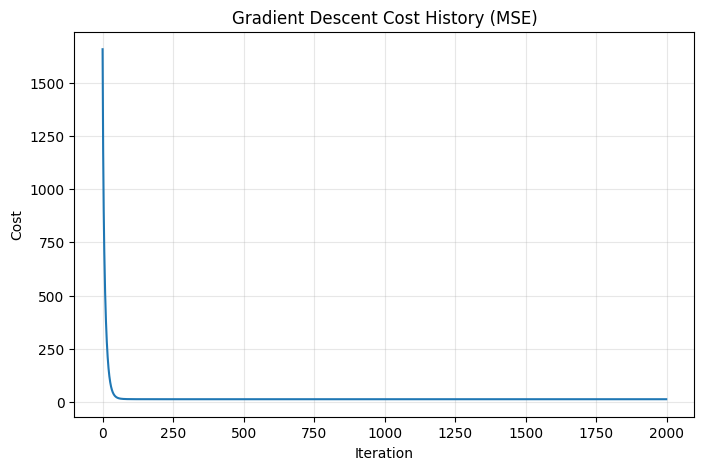

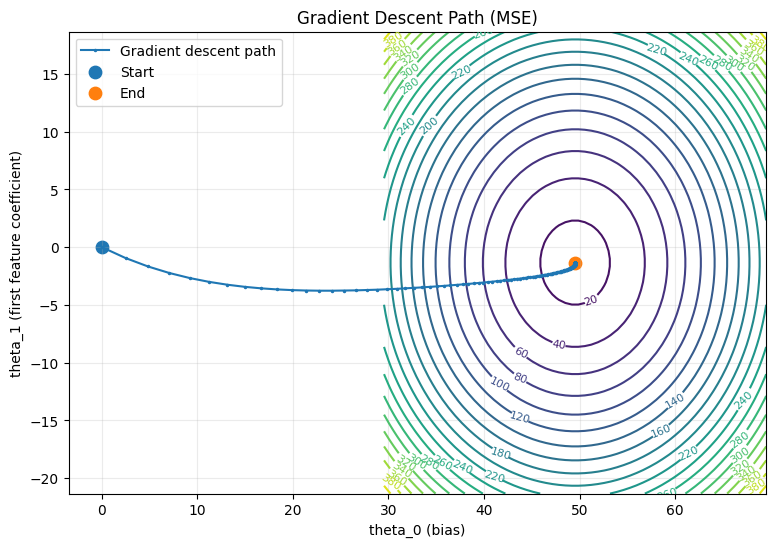

In [ ]:
# Train the scratch implementation using MSE.
scratch_model = LinearRegression(
    learning_rate=0.05,
    num_iterations=2000,
    cost_function="mse"
)

scratch_cost_history = scratch_model.fit(
    X_train,
    y_train,
    verbose=True
)

scratch_predictions = scratch_model.predict(X_test)
scratch_test_mse = scratch_model.score(X_test, y_test)

print(f"\nScratch Linear Regression Test MSE: {scratch_test_mse:.4f}")
print("Learned theta:", scratch_model.theta)

# Visualize convergence.
scratch_model.plot_cost_history()

# Visualize the path using theta_0 and theta_1.
# The remaining coefficients are kept fixed at their final values.
scratch_model.plot_gradient_descent_path(
    X_train,
    y_train,
    theta0_range=(scratch_model.theta[0] - 20, scratch_model.theta[0] + 20),
    theta1_range=(scratch_model.theta[1] - 20, scratch_model.theta[1] + 20),
    resolution=60
)


MSE  | final training cost = 13.313962 | test MSE = 24.1441
MAE  | final training cost = 4.175738 | test MSE = 24.1895
RMSE | final training cost = 5.160233 | test MSE = 24.1366


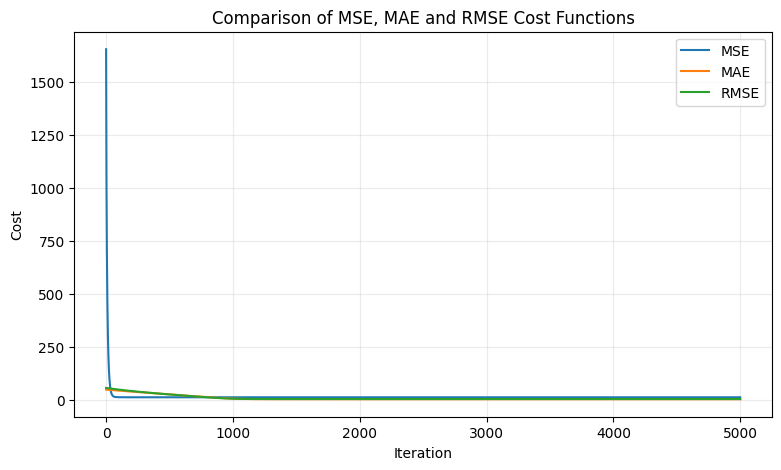

In [ ]:
# Compare the three cost functions on the same dataset.
# The final evaluation metric remains MSE because the assignment asks for MSE on test data.

cost_models = {}

for cost_name in ["mse", "mae", "rmse"]:
    model = LinearRegression(
        learning_rate=0.05,
        num_iterations=5000,
        cost_function=cost_name
    )
    history = model.fit(X_train, y_train, verbose=False)
    test_mse = model.score(X_test, y_test)
    cost_models[cost_name] = (model, history, test_mse)

    print(f"{cost_name.upper():4s} | final training cost = {history[-1]:.6f} "
          f"| test MSE = {test_mse:.4f}")

# Plot the learning curves.
plt.figure(figsize=(9, 5))
for cost_name, (_, history, _) in cost_models.items():
    plt.plot(history, label=cost_name.upper())

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Comparison of MSE, MAE and RMSE Cost Functions")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()


### Part B: Regularized Linear Regression Using Scikit-learn

Now, you'll use the [scikit-learn](https://scikit-learn.org/stable/index.html) to implement [Linear Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html), [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html#sklearn.linear_model.Ridge), [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html#sklearn.linear_model.Lasso), [Elastic Net](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html#sklearn.linear_model.ElasticNet) and apply them to the human-zombie dataset.

Try out different values of regularization coefficient (known as `alpha` in `sklearn`) and use the [Mean Squared Error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html) to report loss with each regression.

Finally, plot the regularization coefficients alpha (x-axis) with learned parameters $\theta$ (y-axis) for Ridge and Lasso. Please read [this blog](https://scienceloft.com/technical/understanding-lasso-and-ridge-regression/) to get better understanding of the desired plots.


#### Importing Libraries

You have to use scikit-learn for this task

In [ ]:
# Part B imports: scikit-learn is allowed in this section.
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt


#### Linear Regression (using `sklearn`)

Use the [Mean Squared Error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html) to find loss and print it.

In [ ]:
# Ordinary Linear Regression (no regularization)
linear_model = SklearnLinearRegression()
linear_model.fit(X_train_scaled, y_train)

linear_predictions = linear_model.predict(X_test_scaled)
linear_mse = mean_squared_error(y_test, linear_predictions)

print(f"Linear Regression Test MSE: {linear_mse:.4f}")
print("Coefficients:", linear_model.coef_)
print("Intercept:", linear_model.intercept_)


Linear Regression Test MSE: 24.1441
Coefficients: [-1.33485563 -0.30918952  2.51206411  7.93334972 -9.83661155 -8.95320687]
Intercept: 49.536502377911276


#### Ridge

Use the [Mean Squared Error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html) to find loss and print it. Also plot the regularization coefficients alpha (x-axis) with learned parameters $\theta$  (y-axis) for Ridge.

Ridge MSE for selected alphas:
alpha=0.0010 -> MSE=24.1441
alpha=0.0108 -> MSE=24.1440
alpha=0.1172 -> MSE=24.1433
alpha=1.2690 -> MSE=24.1357
alpha=13.7382 -> MSE=24.1131
alpha=148.7352 -> MSE=27.1179
alpha=1000.0000 -> MSE=73.8757


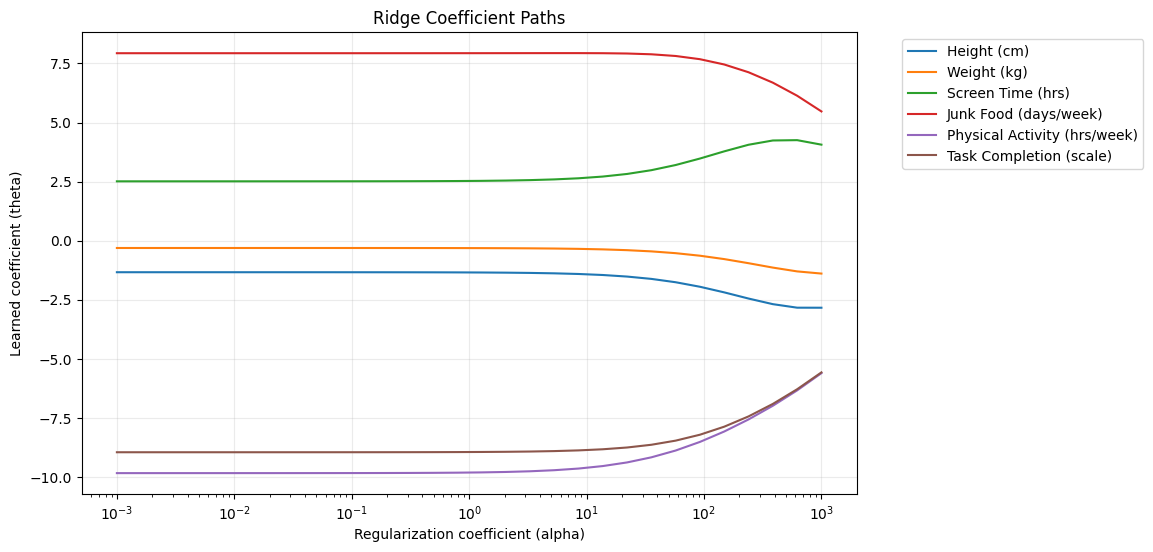


Best Ridge alpha on test set: 8.5317
Best Ridge test MSE: 24.1102


In [ ]:
# Ridge uses L2 regularization.
# We try several alpha values to see how increasing regularization
# changes the learned coefficients.

alphas = np.logspace(-3, 3, 30)
ridge_mse = []
ridge_coefficients = []

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    ridge_mse.append(mean_squared_error(y_test, predictions))
    ridge_coefficients.append(model.coef_)

ridge_coefficients = np.array(ridge_coefficients)

print("Ridge MSE for selected alphas:")
for alpha, mse in zip(alphas[[0, 5, 10, 15, 20, 25, 29]],
                      np.array(ridge_mse)[[0, 5, 10, 15, 20, 25, 29]]):
    print(f"alpha={alpha:.4f} -> MSE={mse:.4f}")

# Coefficient path: alpha on x-axis, each feature coefficient on y-axis.
plt.figure(figsize=(10, 6))
for i, feature in enumerate(X.columns):
    plt.plot(alphas, ridge_coefficients[:, i], label=feature)

plt.xscale("log")
plt.xlabel("Regularization coefficient (alpha)")
plt.ylabel("Learned coefficient (theta)")
plt.title("Ridge Coefficient Paths")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.25)
plt.show()

# The alpha with the lowest test MSE in this experiment.
best_ridge_idx = int(np.argmin(ridge_mse))
print(f"\nBest Ridge alpha on test set: {alphas[best_ridge_idx]:.4f}")
print(f"Best Ridge test MSE: {ridge_mse[best_ridge_idx]:.4f}")


#### Lasso

Use the [Mean Squared Error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html) to find loss and print it. Also plot the regularization coefficients alpha (x-axis) with learned parameters $\theta$  (y-axis) for Lasso.

Lasso MSE for selected alphas:
alpha=0.0010 -> MSE=24.1441
alpha=0.0108 -> MSE=24.1472
alpha=0.1172 -> MSE=24.2073
alpha=1.2690 -> MSE=26.4639
alpha=13.7382 -> MSE=212.2470
alpha=148.7352 -> MSE=785.7266
alpha=1000.0000 -> MSE=785.7266


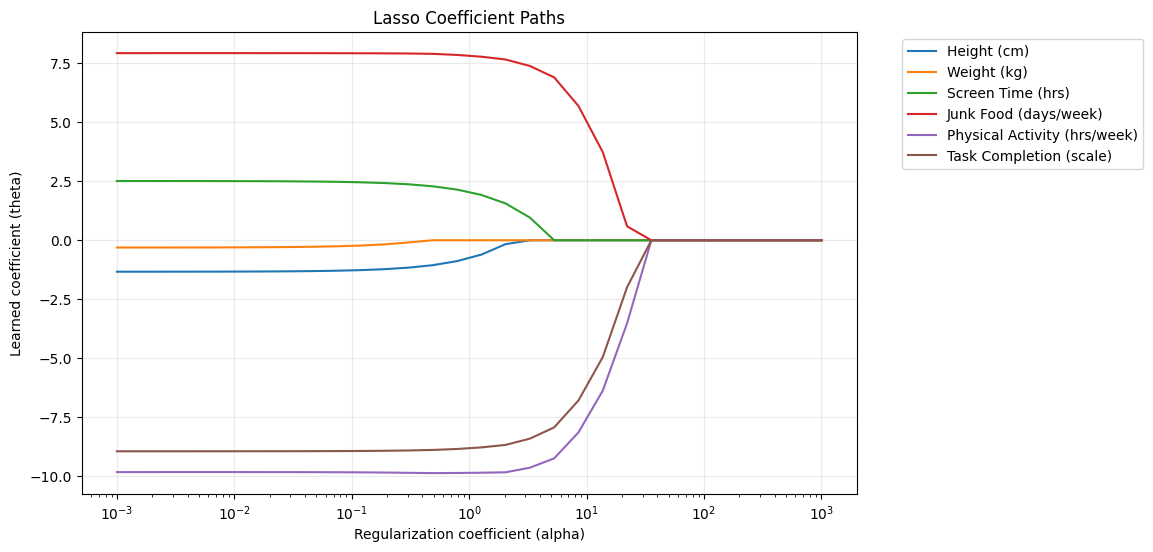


Best Lasso alpha on test set: 0.0010
Best Lasso test MSE: 24.1441


In [ ]:
# Lasso uses L1 regularization.
# L1 can drive some coefficients exactly to zero, which can perform
# automatic feature selection.

lasso_mse = []
lasso_coefficients = []

for alpha in alphas:
    model = Lasso(alpha=alpha, max_iter=10000)
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    lasso_mse.append(mean_squared_error(y_test, predictions))
    lasso_coefficients.append(model.coef_)

lasso_coefficients = np.array(lasso_coefficients)

print("Lasso MSE for selected alphas:")
for alpha, mse in zip(alphas[[0, 5, 10, 15, 20, 25, 29]],
                      np.array(lasso_mse)[[0, 5, 10, 15, 20, 25, 29]]):
    print(f"alpha={alpha:.4f} -> MSE={mse:.4f}")

# Plot how each feature coefficient changes as regularization increases.c
plt.figure(figsize=(10, 6))
for i, feature in enumerate(X.columns):
    plt.plot(alphas, lasso_coefficients[:, i], label=feature)

plt.xscale("log")
plt.xlabel("Regularization coefficient (alpha)")
plt.ylabel("Learned coefficient (theta)")
plt.title("Lasso Coefficient Paths")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.25)
plt.show()

best_lasso_idx = int(np.argmin(lasso_mse))
print(f"\nBest Lasso alpha on test set: {alphas[best_lasso_idx]:.4f}")
print(f"Best Lasso test MSE: {lasso_mse[best_lasso_idx]:.4f}")


#### Elastic Net

Use the [Mean Squared Error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html) to find loss and print it.

In [ ]:
# Elastic Net combines L1 and L2 regularization.
# l1_ratio controls the mixture:
#   0.0 -> mostly Ridge/L2
#   1.0 -> Lasso/L1
#   0.5 -> equal mixture of L1 and L2

elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
elastic_net.fit(X_train_scaled, y_train)

elastic_predictions = elastic_net.predict(X_test_scaled)
elastic_mse = mean_squared_error(y_test, elastic_predictions)

print(f"Elastic Net Test MSE: {elastic_mse:.4f}")
print("Coefficients:", elastic_net.coef_)
print("Intercept:", elastic_net.intercept_)

# Final comparison of all models using their test-set MSE.
best_ridge_mse = min(ridge_mse)
best_lasso_mse = min(lasso_mse)

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge (best alpha)",
        "Lasso (best alpha)",
        "Elastic Net"
    ],
    "Test MSE": [
        linear_mse,
        best_ridge_mse,
        best_lasso_mse,
        elastic_mse
    ]
})

print("\nModel comparison:")
display(comparison.sort_values("Test MSE").reset_index(drop=True))


Elastic Net Test MSE: 24.3576
Coefficients: [-1.62074312 -0.4351474   3.01046056  7.87536749 -9.10565535 -8.59291016]
Intercept: 49.536502377911276

Model comparison:


,Model,Test MSE
0,Ridge (best alpha),24.110224
1,Linear Regression,24.144100
2,Lasso (best alpha),24.144119
3,Elastic Net,24.357629
